# C2 Adaptive Recommendation and Assessment Live Demonstration

This executable notebook runs the **actual isolated integrated C2 backend**. C1 supplies a validated first-attempt response; C2 updates strict-prior learner history, obtains an XGBoost conditional-correctness estimate when eligible, applies curriculum/coverage/readiness policy, issues a robot task, and exports mathematical evidence to C4.


The synthetic response is the only fictional input. Questions, recommendations, probabilities, policy actions, history updates, stopping, and exports come from live engine execution.

## B. Environment and model verification

In [29]:
from pathlib import Path
import hashlib, importlib.util, json, platform, sys
import pandas as pd
import matplotlib.pyplot as plt
import jsonschema

def locate_demo():
    here = Path.cwd().resolve()
    for root in (here, *here.parents):
        isolated = root / "source" / "backend"
        if isolated.is_dir() and (root / "simulations" / "run_adaptive_simulation.py").is_file():
            return root, isolated, root / "simulations" / "run_adaptive_simulation.py"
        backend = root if (root / "app" / "modules" / "adaptive_questions").is_dir() else None
        helper = root / "training" / "adaptive_questions" / "run_adaptive_simulation.py"
        if backend and helper.is_file():
            return root, backend, helper
    raise RuntimeError("Integrated backend and simulation helper were not found")

DEMO_ROOT, BACKEND, HELPER = locate_demo()
spec = importlib.util.spec_from_file_location("c2_demo_runner", HELPER)
runner = importlib.util.module_from_spec(spec); spec.loader.exec_module(runner)
preflight = runner.source_preflight()
assert preflight["all_required_files_present"] and preflight["all_manifest_hashes_match"]
assert BACKEND.resolve() == runner.BACKEND.resolve()

settings = preflight["assessment_settings"]
pd.DataFrame([{
    "Python": platform.python_version(),
    "Backend": str(BACKEND.resolve()),
    "Inside Version 13": "13_C2_Adaptive_Engine_Demonstration" in str(BACKEND.resolve()),
    "Model": preflight["model_version"],
    "Artifacts verified": preflight["all_manifest_hashes_match"],
    "Budget": f'{settings["minimum_total_valid_responses"]}-{settings["maximum_total_interactions"]} valid responses',
    "Advance threshold": settings["advance_probability_threshold"],
}])

,Python,Backend,Inside Version 13,Model,Artifacts verified,Budget,Advance threshold
0,3.12.7,C:\Users\Monil A\Documents\GitHub\J26-DS-330-A...,False,TRANSFER_H2_GB_RT_OFF_v1,True,16-24 valid responses,0.75


## C. Student configuration

Choose Grade 1â€“5 and one deterministic fictional profile. Fixed seeds make the response sequence reproducible.

In [30]:
GRADE = 3
PROFILE = "Strong"  # Strong, Struggling, Average, Inconsistent, Improving
BASE_SEED = 20261018
assert 1 <= GRADE <= 5
assert PROFILE in runner.PROFILES
{"grade": GRADE, "profile": PROFILE, "base_seed": BASE_SEED}

{'grade': 3, 'profile': 'Strong', 'base_seed': 20261018}

## D. Actual assessment execution

`execute_simulation` repeatedly calls `Component2Service.next_task`, generates only the fictional response, then submits it through `TeamContractAdapter.ingest(AssessmentEvent, CubeAssessmentResult)`. It never forces a game, tier, model probability, or stopping decision.

In [31]:
run = runner.execute_simulation("one", GRADE, PROFILE, BASE_SEED, write_outputs=False)
summary = run["summaries"][0]
trace = pd.DataFrame(run["traces"])
c4_export = run["exports"][0]
validation = run["validations"][0]
assert validation["passed"]
summary

{'learner_id': 'SIM-G3-STRONG-01',
 'grade': 3,
 'simulated_performance_profile': 'Strong',
 'deterministic_seed': 20261319,
 'session_id': 'ca895026-f35b-461e-8181-c4c447400734',
 'total_valid_questions': 22,
 'correct_responses': 19,
 'incorrect_responses': 3,
 'correctness_percentage': 86.36,
 'games_assessed': 'ADDITION|COMPARISON|COUNTING|DIVISION|MULTIPLICATION|ORDERING|PLACE_VALUE|SUBTRACTION',
 'mathematical_areas_assessed': 'Arithmetic calculation|Multiplicative reasoning|Number relationships|Number sense',
 'tier_a_count': 21,
 'tier_b_count': 1,
 'xgboost_recommendation_count': 21,
 'beta_bernoulli_count': 0,
 'fallback_abstention_count': 1,
 'final_assessment_status': 'COMPLETE',
 'stopping_reason': 'SUFFICIENT_EVIDENCE_AFTER_MINIMUM_VALID_RESPONSES',
 'c4_export_validation_result': 'PASS'}

## E. Question-by-question results

The probability on row *q* is calculated before response *q* is observed. `history_count` is therefore qâˆ’1 (visible in the stored recommendation provenance), preventing current-response leakage.

In [32]:
table = trace.rename(columns={
    "question_number":"Q", "game_id":"Game", "mathematical_assessment_area":"Area",
    "difficulty_tier":"Tier", "correctness":"Correct", "predicted_probability":"Predicted p",
    "prediction_source":"Provenance", "decision_type":"Action",
    "recommendation_reason":"Reason", "assessment_status_after_response":"Status",
})
table["Predicted p"] = table["Predicted p"].map(lambda x: None if pd.isna(x) else round(float(x), 4))
table["Coverage"] = table["coverage_after_response"].map(lambda x: json.loads(x)["valid"])
table[["Q","Game","Area","Tier","Correct","Predicted p","Provenance","Action","Coverage","Status"]]

,Q,Game,Area,Tier,Correct,Predicted p,Provenance,Action,Coverage,Status
0,1,COUNTING,Number sense,Tier A,1,NaN,ABSTAIN,START,1,IN_PROGRESS
1,2,COUNTING,Number sense,Tier A,1,0.8043,TRAINED_ML,CONTINUE,2,IN_PROGRESS
2,3,COUNTING,Number sense,Tier A,1,0.8595,TRAINED_ML,CONTINUE,3,IN_PROGRESS
3,4,COUNTING,Number sense,Tier B,1,0.8435,TRAINED_ML,ADVANCE,4,IN_PROGRESS
4,5,PLACE_VALUE,Number relationships,Tier A,1,0.7140,TRAINED_ML,SWITCH,5,IN_PROGRESS
5,6,ADDITION,Arithmetic calculation,Tier A,0,0.7226,TRAINED_ML,SWITCH,6,IN_PROGRESS
6,7,MULTIPLICATION,Multiplicative reasoning,Tier A,0,0.6341,TRAINED_ML,SWITCH,7,IN_PROGRESS
7,8,COMPARISON,Number sense,Tier A,1,0.5237,TRAINED_ML,SWITCH,8,IN_PROGRESS
8,9,SUBTRACTION,Arithmetic calculation,Tier A,1,0.6095,TRAINED_ML,SWITCH,9,IN_PROGRESS
9,10,ORDERING,Number sense,Tier A,1,0.6442,TRAINED_ML,SWITCH,10,IN_PROGRESS


## F. Visualizations

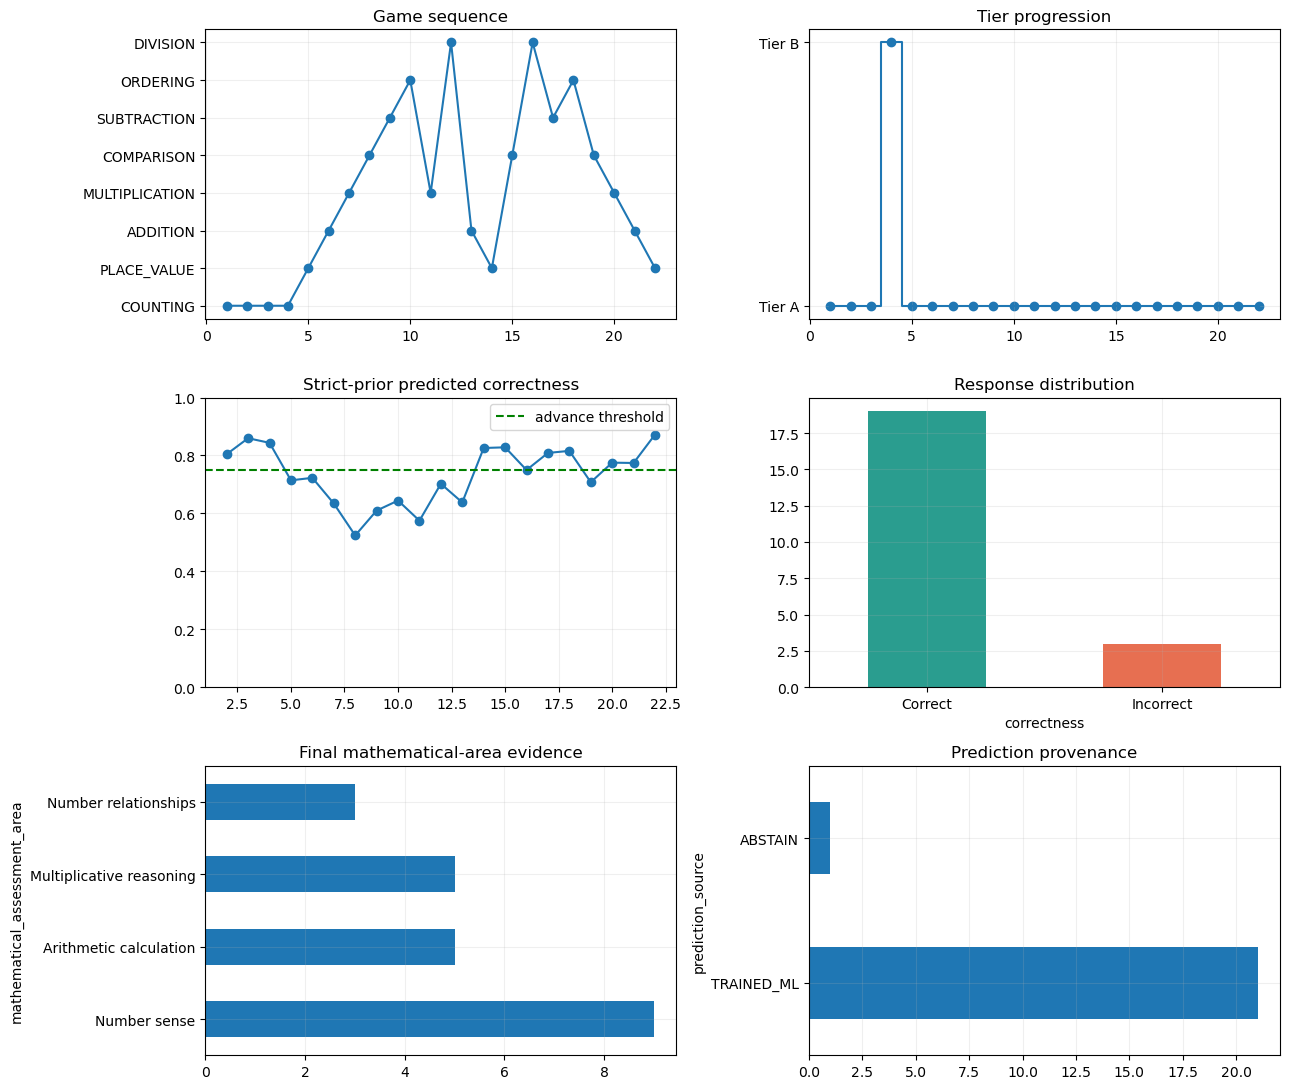

In [33]:
games = list(dict.fromkeys(trace["game_id"]))
game_y = trace["game_id"].map({g:i for i,g in enumerate(games)})
tier_y = trace["difficulty_tier"].map({"Tier A":0, "Tier B":1})
fig, axes = plt.subplots(3, 2, figsize=(13, 11))
q = trace["question_number"]
axes[0,0].plot(q, game_y, marker="o"); axes[0,0].set_yticks(range(len(games)), games); axes[0,0].set_title("Game sequence")
axes[0,1].step(q, tier_y, where="mid"); axes[0,1].scatter(q, tier_y); axes[0,1].set_yticks([0,1],["Tier A","Tier B"]); axes[0,1].set_title("Tier progression")
axes[1,0].plot(q, trace["predicted_probability"], marker="o"); axes[1,0].axhline(settings["advance_probability_threshold"], ls="--", color="green", label="advance threshold"); axes[1,0].set_ylim(0,1); axes[1,0].legend(); axes[1,0].set_title("Strict-prior predicted correctness")
trace["correctness"].value_counts().reindex([1,0], fill_value=0).plot.bar(ax=axes[1,1], color=["#2a9d8f","#e76f51"]); axes[1,1].set_xticklabels(["Correct","Incorrect"], rotation=0); axes[1,1].set_title("Response distribution")
trace["mathematical_assessment_area"].value_counts().plot.barh(ax=axes[2,0]); axes[2,0].set_title("Final mathematical-area evidence")
trace["prediction_source"].value_counts().plot.barh(ax=axes[2,1]); axes[2,1].set_title("Prediction provenance")
for ax in axes.flat: ax.grid(alpha=.2)
fig.tight_layout(); plt.show()

## G. Final session report

In [34]:
final_report = pd.DataFrame([{
    "Grade": summary["grade"], "Profile": summary["simulated_performance_profile"],
    "Questions": summary["total_valid_questions"], "Correct": summary["correct_responses"],
    "Incorrect": summary["incorrect_responses"], "Accuracy %": summary["correctness_percentage"],
    "Games": len(summary["games_assessed"].split("|")), "Areas": len(summary["mathematical_areas_assessed"].split("|")),
    "Tier A": summary["tier_a_count"], "Tier B": summary["tier_b_count"],
    "XGBoost": summary["xgboost_recommendation_count"], "Fallback/abstain": summary["fallback_abstention_count"],
    "Status": summary["final_assessment_status"], "Stopping reason": summary["stopping_reason"],
}])
final_report

,Grade,Profile,Questions,Correct,Incorrect,Accuracy %,Games,Areas,Tier A,Tier B,XGBoost,Fallback/abstain,Status,Stopping reason
0,3,Strong,22,19,3,86.36,8,4,21,1,21,1,COMPLETE,SUFFICIENT_EVIDENCE_AFTER_MINIMUM_VALID_RESPONSES


## H. C4 evidence export and schema validation

In [35]:
schema_path = BACKEND / "app" / "modules" / "adaptive_questions" / "contracts" / "c2_to_c4_profile.schema.json"
schema = json.loads(schema_path.read_text(encoding="utf-8"))
jsonschema.validate(c4_export, schema)
c4_summary = {
    "schema_version": c4_export["schema_version"],
    "learner_id": c4_export["learner_id"],
    "session_id": c4_export["session_id"],
    "grade": c4_export["profile"]["grade"],
    "valid_evidence_rows": len(c4_export["profile"]["response_evidence"]),
    "assessment_status": c4_export["profile"]["assessment"]["status"],
    "stopping_reason": c4_export["profile"]["assessment"]["stopping_reason"],
    "not_a_diagnosis": c4_export["semantics"]["not_a_diagnosis"],
    "schema_validation": "PASS",
}
c4_summary

{'schema_version': 'C2_TO_C4_v2.0.0',
 'learner_id': 'SIM-G3-STRONG-01',
 'session_id': 'ca895026-f35b-461e-8181-c4c447400734',
 'grade': 3,
 'valid_evidence_rows': 22,
 'assessment_status': 'COMPLETE',
 'stopping_reason': 'SUFFICIENT_EVIDENCE_AFTER_MINIMUM_VALID_RESPONSES',
 'not_a_diagnosis': True,
 'schema_validation': 'PASS'}

## Safety fallback verification

In [36]:
from backend.app.modules.adaptive_questions.feature_engineering.learner_state import make_learner_state
from backend.app.modules.adaptive_questions.prediction.predictor import PredictorRouter, TransferableTrainedPredictor

skill = "Counting / subitizing"
fallback_state = make_learner_state(
    learner_id="FALLBACK-DEMO", current_grade=3, current_skill_context=skill,
    prior_interaction_count=2, prior_correct_count=1, recent_outcomes=(1,0),
    recent_skill_outcomes=(1,0), recent_skill_outcomes_by_skill={skill:(1,0)},
    prior_skill_exposures={skill:2}, prior_skill_correct={skill:1},
    tier_a_exposures={skill:2}, tier_a_correct={skill:1}, interactions_since_last_correct=1,
)
missing_artifacts = DEMO_ROOT / "simulations" / "temporary_data" / "deliberately_missing_model"
fallback_result = PredictorRouter(TransferableTrainedPredictor(missing_artifacts)).predict(fallback_state, skill)
assert fallback_result["source"] == "BETA_BERNOULLI_FALLBACK"
fallback_result

{'model_version': 'LOCAL_BETA_BERNOULLI_v1',
 'target': 'next local response correctness for the same operational skill',
 'skill': 'Counting / subitizing',
 'evidence_count': 2,
 'correct_count': 1,
 'uses_strict_prior_history': True,
 'validation_status': 'EXPERIMENTAL_UNVALIDATED_FOR_REAL_CHILDREN',
 'success_probability': 0.5,
 'posterior_standard_deviation': 0.22360679774997896,
 'abstention_reason': None,
 'source': 'BETA_BERNOULLI_FALLBACK',
 'valid': True,
 'primary_abstention_reason': 'ARTIFACT_LOAD_FAILED:FileNotFoundError'}

## I. Interpretation

This run establishes that the integrated backend imports from the isolated source, validates frozen artifacts, uses strict-prior learner history, performs genuine saved-XGBoost inference after cold start, filters by grade/curriculum/readiness, issues real robot tasks, respects the evidence-based 16â€“24 policy, and produces a schema-valid C4 export. The explicit unavailable-artifact check demonstrates the local-history safety fallback.

It does **not** establish dyscalculia probability, diagnosis, clinical validity, local-child calibration, causal learning benefit, or real-world generalization. Predicted probability means conditional next-response correctness under the transferred ASSISTments feature semantics.